# 01 · Série sintética: geração e comportamento

Este notebook gera a série usada no experimento e analisa o seu comportamento. As figuras são salvas em `results/figuras/` no mesmo tema escuro dos slides.

**Processo gerador (DGP):**

$$y_t = 0{,}4\,y_{t-1} + 0{,}3\,y_{t-24} + 0{,}2\,y_{t-168} + 0{,}1\,y_{t-720} + \varepsilon_t, \qquad \varepsilon_t \sim \mathcal{N}(0, \sigma^2)$$

| lag | interpretação (dados horários) |
|---|---|
| 1 | 1 hora (curto prazo) |
| 24 | 1 dia |
| 168 | 1 semana |
| 720 | ~30 dias |

Os coeficientes e lags são **parâmetros do processo gerador**: controlam a estrutura de dependência temporal. Não devem ser lidos como "40% de dependência".

Roteiro:
1. Configuração
2. Geração da série
3. Visualização (série completa e zooms)
4. Estrutura de dependência por lag
5. Autocorrelação (ACF)
6. Dispersão yₜ × yₜ₋ₗₐ₉
7. Estacionariedade
8. Salvar os dados

## 1. Configuração

Tudo o que define a série está nesta célula. Para testar outros cenários, basta mudar os valores aqui.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- parâmetros do processo gerador ----------------
LAGS   = [1, 24, 168, 720]          # defasagens (horas)
COEFS  = [0.4, 0.3, 0.2, 0.1]       # coeficientes de cada defasagem
SIGMA  = 0.1                        # desvio-padrão do ruído ε_t
N      = 12_000                     # tamanho da série que vamos usar
WARMUP = 2_000                      # passos descartados no início (transiente)
SEED   = 42                         # semente: garante reprodutibilidade

# ---------------- pastas ----------------
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "results" / "figuras"
DATA_DIR = ROOT / "dados"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
print("Pasta do projeto:", ROOT)

Pasta do projeto: /home/claude/proj


### Estilo dos gráficos (mesmo tema escuro da apresentação)

In [2]:
BG, FG, MUTED, GRID = "#141A24", "#E6E8EE", "#8B93A1", "#252D3A"
ACC, ACC2 = "#8FA8FF", "#C4B5FD"     # azul (destaque) e lilás (secundário)

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "axes.edgecolor": MUTED,
    "axes.labelcolor": FG, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": FG,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 12, "legend.frameon": False, "savefig.dpi": 200,
})

def salvar(fig, nome):
    """Salva a figura em results/figuras/ para usar nos slides."""
    caminho = FIG_DIR / f"{nome}.png"
    fig.savefig(caminho, bbox_inches="tight")
    print("figura salva em", caminho.relative_to(ROOT))

## 2. Geração da série

A geração é um laço direto sobre a equação do DGP:

1. começamos com `y = 0` nos primeiros `max(LAGS)` passos (não há passado para olhar);
2. para cada `t`, somamos `coef × y[t − lag]` para cada defasagem e adicionamos o ruído `ε_t`;
3. descartamos o **warmup**: os primeiros passos ainda "lembram" do início artificial em zero, e só depois a série entra no seu comportamento típico.

In [3]:
def gerar_serie(lags, coefs, sigma, n, warmup, seed):
    rng = np.random.default_rng(seed)
    max_lag = max(lags)
    total = max_lag + warmup + n
    y = np.zeros(total)
    eps = rng.normal(0.0, sigma, total)          # ruído gaussiano ε_t
    for t in range(max_lag, total):
        y[t] = sum(c * y[t - l] for l, c in zip(lags, coefs)) + eps[t]
    inicio = max_lag + warmup                    # descarta zeros iniciais + warmup
    return y[inicio:]

y = gerar_serie(LAGS, COEFS, SIGMA, N, WARMUP, SEED)
t = np.arange(len(y))

print(f"tamanho: {len(y)} pontos  (~{len(y)/24:.0f} dias de dados horários)")
pd.Series(y, name="y").describe().round(4)

tamanho: 12000 pontos  (~500 dias de dados horários)


count    12000.0000
mean        -0.0600
std          0.1398
min         -0.5632
25%         -0.1558
50%         -0.0590
75%          0.0336
max          0.4302
Name: y, dtype: float64

## 3. Visualização

Primeiro a série inteira, depois dois zooms: **1 semana** (168 h), onde aparece o ciclo diário, e **1 mês** (720 h).

figura salva em results/figuras/serie_completa.png


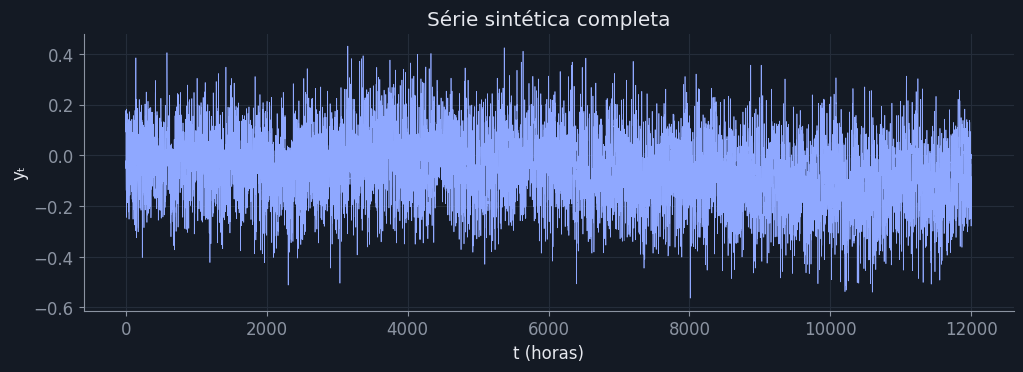

In [4]:
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(t, y, color=ACC, lw=0.5)
ax.set(title="Série sintética completa", xlabel="t (horas)", ylabel="yₜ")
salvar(fig, "serie_completa"); plt.show()

figura salva em results/figuras/serie_zooms.png


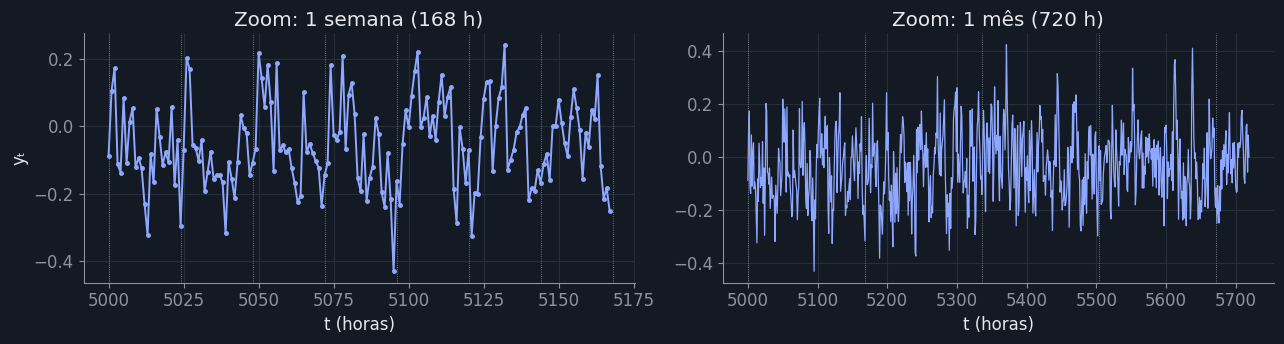

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
ini = 5_000
axs[0].plot(t[ini:ini+168], y[ini:ini+168], color=ACC, lw=1.4, marker="o", ms=2.5)
axs[0].set(title="Zoom: 1 semana (168 h)", xlabel="t (horas)", ylabel="yₜ")
for k in range(ini, ini + 169, 24):              # linhas a cada 24 h
    axs[0].axvline(k, color=MUTED, lw=0.6, ls=":")
axs[1].plot(t[ini:ini+720], y[ini:ini+720], color=ACC, lw=0.9)
axs[1].set(title="Zoom: 1 mês (720 h)", xlabel="t (horas)")
for k in range(ini, ini + 721, 168):             # linhas a cada semana
    axs[1].axvline(k, color=MUTED, lw=0.6, ls=":")
fig.tight_layout(); salvar(fig, "serie_zooms"); plt.show()

## 4. Estrutura de dependência por lag

Este é o "gabarito" do experimento: onde estão as dependências verdadeiras. Um modelo com contexto L só consegue "ver" os lags ≤ L.

figura salva em results/figuras/serie_dependencias.png


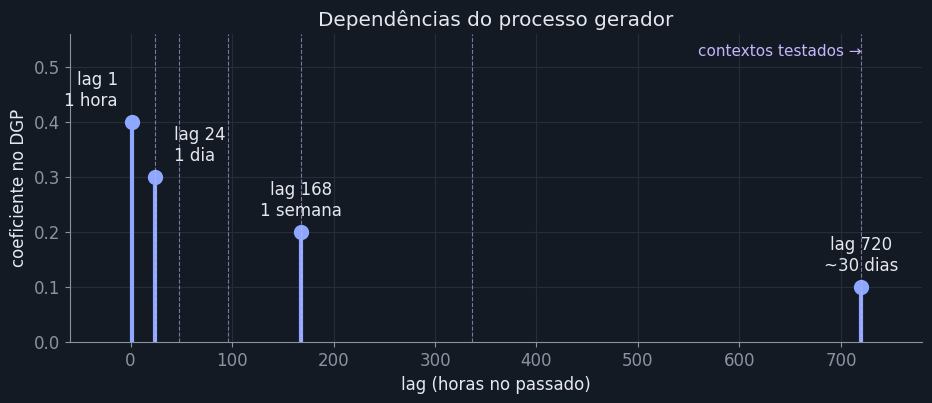

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.vlines(LAGS, 0, COEFS, color=ACC, lw=3)
ax.plot(LAGS, COEFS, "o", color=ACC, ms=10)
nomes = ["1 hora", "1 dia", "1 semana", "~30 dias"]
for l, c, nome, dx, ha in zip(LAGS, COEFS, nomes, [-10, 14, 0, 0], ["right", "left", "center", "center"]):
    ax.annotate(f"lag {l}\n{nome}", (l, c), xytext=(dx, 12), textcoords="offset points", ha=ha)
for L in [24, 48, 96, 168, 336, 720]:            # contextos do experimento
    ax.axvline(L, color=ACC2, lw=0.8, ls="--", alpha=0.6)
ax.text(720, 0.52, "contextos testados →", color=ACC2, ha="right", fontsize=11)
ax.set(xlim=(-60, 780), ylim=(0, 0.56), xlabel="lag (horas no passado)",
       ylabel="coeficiente no DGP", title="Dependências do processo gerador")
salvar(fig, "serie_dependencias"); plt.show()

## 5. Autocorrelação (ACF)

A autocorrelação no lag k mede o quanto yₜ se parece com yₜ₋ₖ. Esperamos **picos nos lags 24, 168 e 720** e também em combinações deles (48 = 24+24, 192 = 168+24, …), porque as dependências se propagam pela dinâmica.

figura salva em results/figuras/serie_acf.png


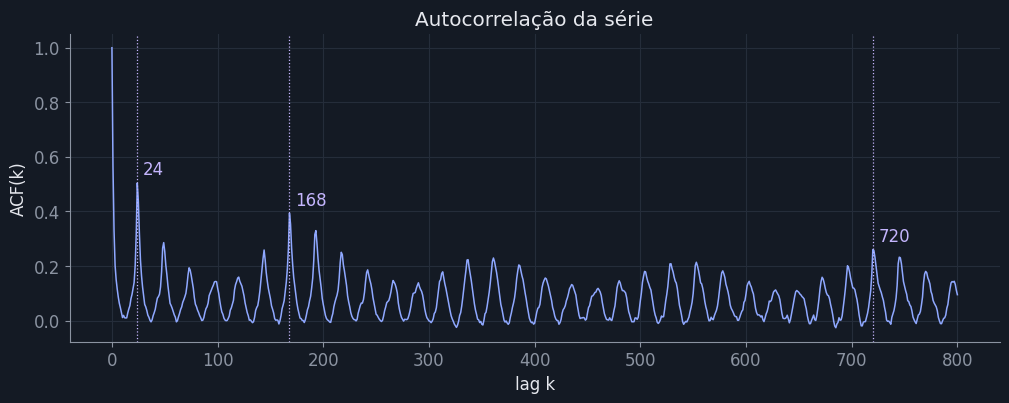

ACF nos lags do DGP: {1: 0.566, 24: 0.504, 168: 0.393, 720: 0.26}


In [7]:
def acf(x, max_lag):
    """Autocorrelação via FFT (rápida mesmo para 800 lags)."""
    x = x - x.mean()
    f = np.fft.rfft(x, 2 * len(x))
    r = np.fft.irfft(f * np.conj(f))[: max_lag + 1]
    return r / r[0]

r = acf(y, 800)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(np.arange(len(r)), r, color=ACC, lw=1.1)
for l in LAGS[1:]:
    ax.axvline(l, color=ACC2, lw=0.9, ls=":")
    ax.annotate(f"{l}", (l, r[l]), xytext=(4, 6), textcoords="offset points", color=ACC2)
ax.set(xlabel="lag k", ylabel="ACF(k)", title="Autocorrelação da série")
salvar(fig, "serie_acf"); plt.show()

print("ACF nos lags do DGP:", {l: round(float(r[l]), 3) for l in LAGS})

## 6. Dispersão yₜ × yₜ₋ₗₐ₉

Outra forma de ver a dependência: cada ponto é um par (yₜ₋ₗₐ₉, yₜ). Quanto mais "alongada" a nuvem, maior a correlação.

figura salva em results/figuras/serie_dispersao_lags.png


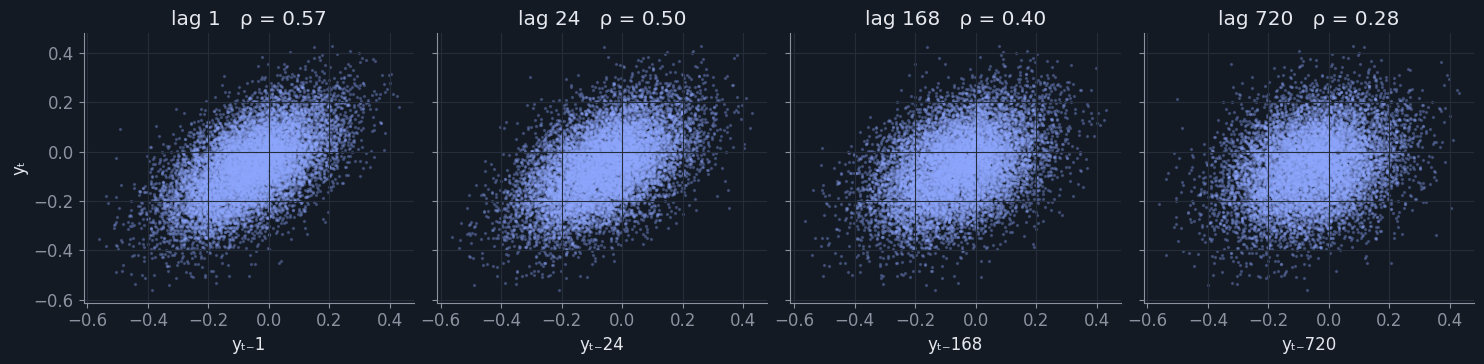

In [8]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, l in zip(axs, LAGS):
    ax.scatter(y[:-l], y[l:], s=2, color=ACC, alpha=0.25)
    rho = np.corrcoef(y[:-l], y[l:])[0, 1]
    ax.set(title=f"lag {l}   ρ = {rho:.2f}", xlabel=f"yₜ₋{l}")
axs[0].set_ylabel("yₜ")
fig.tight_layout(); salvar(fig, "serie_dispersao_lags"); plt.show()

## 7. Estacionariedade

Uma série é (fracamente) **estacionária** quando média e variância não mudam com o tempo. Para um processo autorregressivo, a condição é que todas as raízes do polinômio característico

$$\phi(z) = 1 - 0{,}4\,z - 0{,}3\,z^{24} - 0{,}2\,z^{168} - 0{,}1\,z^{720}$$

estejam **fora** do círculo unitário (|z| > 1). Uma condição suficiente simples é $\sum |\alpha_i| < 1$.

**Atenção:** com os coeficientes 0,4 + 0,3 + 0,2 + 0,1 a soma é **exatamente 1**, então $\phi(1) = 0$: há uma **raiz unitária**. As células abaixo verificam isso de três formas e comparam com a versão corrigida (coeficientes × 0,95).

In [9]:
soma = sum(abs(c) for c in COEFS)
print(f"Soma dos |coeficientes| = {soma:.4f}")
print(f"φ(1) = 1 − soma = {1 - sum(COEFS):.4f}   →  {'raiz unitária (z = 1)!' if abs(1 - sum(COEFS)) < 1e-9 else 'sem raiz em z = 1'}")

def menor_raiz(lags, coefs):
    """Menor |z| entre as raízes de φ(z) (via autovalores da matriz companheira)."""
    p = max(lags)
    phi = np.zeros(p)
    for l, c in zip(lags, coefs):
        phi[l - 1] = c
    F = np.zeros((p, p)); F[0] = phi; F[1:, :-1] = np.eye(p - 1)
    autoval = np.linalg.eigvals(F)          # autovalores λ = 1/z
    return 1 / np.abs(autoval).max()

COEFS_095 = [c * 0.95 for c in COEFS]
print(f"menor |raiz|, coeficientes originais: {menor_raiz(LAGS, COEFS):.4f}   (precisa ser > 1)")
print(f"menor |raiz|, coeficientes × 0,95   : {menor_raiz(LAGS, COEFS_095):.4f}")

Soma dos |coeficientes| = 1.0000
φ(1) = 1 − soma = 0.0000   →  raiz unitária (z = 1)!


menor |raiz|, coeficientes originais: 1.0000   (precisa ser > 1)


menor |raiz|, coeficientes × 0,95   : 1.0004


In [10]:
import warnings
from statsmodels.tsa.stattools import adfuller
warnings.filterwarnings("ignore", category=FutureWarning)

y095 = gerar_serie(LAGS, COEFS_095, SIGMA, N, WARMUP, SEED)   # mesma semente, só muda o coeficiente
for nome, serie in [("original (soma = 1)", y), ("× 0,95 (soma = 0,95)", y095)]:
    stat, pvalor, *_ = adfuller(serie, maxlag=30)
    print(f"ADF {nome:22s}: estatística = {stat:7.2f}   p-valor = {pvalor:.4f}")
print("\nObservação: o ADF rejeita a raiz unitária nas DUAS séries. Isso não contradiz a análise algébrica:"
      "\no ADF usa só até 30 defasagens e não enxerga os lags 168 e 720, onde está a raiz unitária."
      "\nPor isso a verificação pelas raízes de φ(z) é a que vale aqui.")

ADF original (soma = 1)   : estatística =   -8.50   p-valor = 0.0000


ADF × 0,95 (soma = 0,95)  : estatística =  -11.19   p-valor = 0.0000

Observação: o ADF rejeita a raiz unitária nas DUAS séries. Isso não contradiz a análise algébrica:
o ADF usa só até 30 defasagens e não enxerga os lags 168 e 720, onde está a raiz unitária.
Por isso a verificação pelas raízes de φ(z) é a que vale aqui.


figura salva em results/figuras/serie_media_movel.png


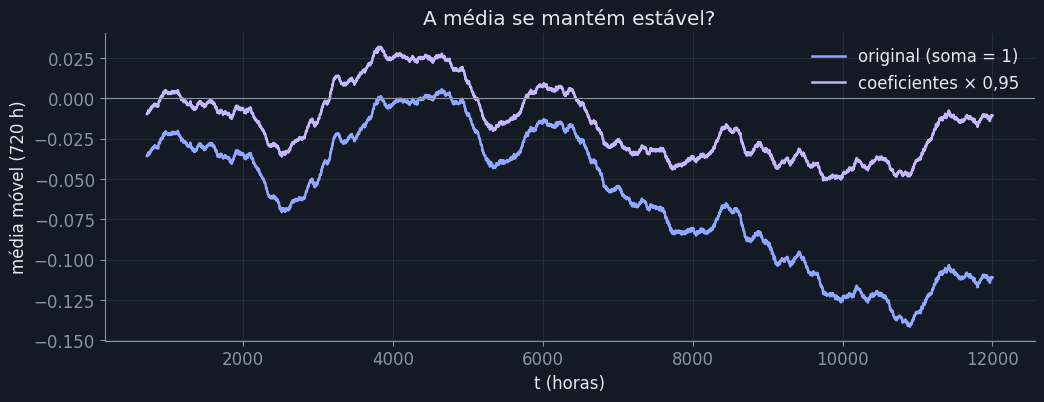

original : média 1ª metade = -0.027   2ª metade = -0.093
× 0,95   : média 1ª metade = +0.001   2ª metade = -0.029


In [11]:
janela = 720   # média móvel de ~1 mês
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(pd.Series(y).rolling(janela).mean(), color=ACC, lw=1.8, label="original (soma = 1)")
ax.plot(pd.Series(y095).rolling(janela).mean(), color=ACC2, lw=1.8, label="coeficientes × 0,95")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set(xlabel="t (horas)", ylabel="média móvel (720 h)", title="A média se mantém estável?")
ax.legend(loc="upper right")
salvar(fig, "serie_media_movel"); plt.show()

metade = len(y) // 2
for nome, s in [("original", y), ("× 0,95", y095)]:
    print(f"{nome:9s}: média 1ª metade = {s[:metade].mean():+.3f}   2ª metade = {s[metade:].mean():+.3f}")

**Como ler:** na série original a média se afasta de zero e não volta (de −0,03 para −0,11): é o efeito da raiz unitária. Na versão × 0,95 a média também oscila, porque a menor raiz (≈ 1,0004) está muito perto de 1 e a volta à média é lenta, mas ela **retorna** para perto de zero. A escolha dos coeficientes é uma decisão do trabalho; esta análise serve para justificá-la na apresentação.

## 8. Salvar os dados

Salvamos a série em CSV para os próximos notebooks (e para a entrega no Classroom).

In [12]:
df = pd.DataFrame({"t": t, "y": y})
caminho = DATA_DIR / "serie_sintetica.csv"
df.to_csv(caminho, index=False, float_format="%.6f")
print("dados salvos em", caminho.relative_to(ROOT))
print("coeficientes usados:", dict(zip(LAGS, COEFS)))

dados salvos em dados/serie_sintetica.csv
coeficientes usados: {1: 0.4, 24: 0.3, 168: 0.2, 720: 0.1}


## Figuras geradas para os slides

| arquivo | uso sugerido |
|---|---|
| `serie_completa.png` / `serie_zooms.png` | slide "Dataset sintético" |
| `serie_dependencias.png` | slide "Dataset sintético" ou "Formulação do experimento" |
| `serie_acf.png` | mostrar que as dependências longas existem nos dados |
| `serie_dispersao_lags.png` | intuição visual de cada lag |
| `serie_media_movel.png` | justificar a escolha dos coeficientes (estacionariedade) |